# CIVIA: risco de barreira de acessibilidade para pessoas cegas e surdas

Este é o modelo de Machine Learning que fiz para o CIVIA, nosso projeto para a CitizenTech.

**Integrantes:** Ana Luiza Santana da Rocha (RM561194), Evandro Yuji Kaibara de Oliveira (RM559274), Guilherme Rodrigues Leite (RM560131), Luís Filipe Crivellaro (RM560877) e Pedro Henrique Batista Bergamin (RM559443).

**Problema.** Quem é cego ou surdo e anda pela cidade encontra trechos que parecem comuns para os outros e são perigosos para ele. Um cruzamento sem sinal sonoro é uma barreira para uma pessoa cega. Uma rua escura, de muito tráfego e sem aviso visual é uma barreira para uma pessoa surda, que não ouve os carros.

**Pergunta do modelo.** Dadas as características de um trecho urbano e o perfil do pedestre (cego ou surdo), qual o nível de barreira: `low`, `medium` ou `high`?

**Quem usa a previsão.** O app da CitizenTech, ao sugerir rotas. Cada trecho recebe um nível e a rota herda o pior deles.

**Como rodar.** `pip install -r requirements.txt`, depois executar o notebook de cima para baixo. Ele gera os dados, treina e salva `model.joblib` e `metrics.json`.

## 1. Dados e origem

Não encontrei uma base pública que traga, por trecho de calçada, sinal sonoro, piso tátil, ruído, iluminação e tráfego junto com um rótulo de dificuldade por perfil de deficiência. Por isso os dados são **simulados** (a atividade permite), com semente fixa (`seed=42`) em `generate_data.py`.

A regra de simulação vem de como cada perfil se orienta. Para pessoas cegas contam piso tátil, sinal sonoro em travessias, sinalização em braille, obstáculos e ruído que cobre os sons do ambiente. Para pessoas surdas contam sinal visual, avisos visuais, iluminação e tráfego intenso, já que elas não ouvem os veículos. Largura, inclinação e escadas pesam para os dois. Entra ruído gaussiano na pontuação, e 4% dos valores de ruído e iluminação ficam vazios, como acontece quando um sensor falha.

**Limite que precisa ficar claro:** como o rótulo sai de uma regra que eu mesmo escrevi, a métrica abaixo mede se o modelo recupera essa regra a partir dos dados, não se ele acerta a realidade de uma cidade. Com dados de campo (mapeamentos de calçadas, relatos de usuários) o mesmo pipeline serviria, mas o número final seria menor.

In [1]:
import json
import pathlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from generate_data import generate

SEED = 42
df = generate()
pathlib.Path("data").mkdir(exist_ok=True)
df.to_csv("data/accessibility_segments.csv", index=False)
df.head()

,profile,segment_type,tactile_paving,audible_signal,visual_signal,braille_signage,visual_alerts,sidewalk_width_m,obstacles_per_100m,slope_pct,ambient_noise_db,lighting_lux,traffic_vehicles_per_min,barrier_level
0,blind,transit_stop,0,0,0,1,1,2.29,1,12.2,72.9,44.4,16,medium
1,deaf,stairs_ramp,0,1,0,0,0,1.17,3,8.1,66.2,29.9,14,high
2,deaf,crossing,1,0,0,0,0,2.57,2,4.1,66.5,25.3,11,high
3,blind,crossing,0,0,1,0,1,3.52,3,3.8,73.7,45.9,8,high
4,blind,plaza,0,0,1,0,0,1.12,1,2.6,92.4,26.8,10,high


In [2]:
print(df.shape)
print(df.isna().sum()[lambda s: s > 0])
print(df["barrier_level"].value_counts(normalize=True).round(3))

(3000, 14)
ambient_noise_db    119
lighting_lux        113
dtype: int64
barrier_level
medium    0.45
low       0.30
high      0.25
Name: proportion, dtype: float64


## 2. Análise e preparação

Três perguntas guiam a análise: as classes estão equilibradas, os perfis sofrem barreiras diferentes, e quais variáveis separam os níveis?

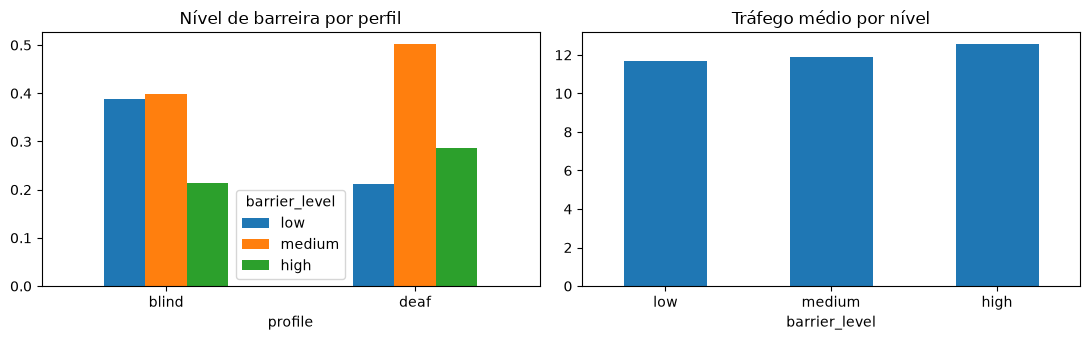

profile  tactile_paving
blind    0                 0.36
         1                 0.03
deaf     0                 0.30
         1                 0.27
Name: barrier_level, dtype: float64


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
pd.crosstab(df["profile"], df["barrier_level"], normalize="index")[["low", "medium", "high"]].plot.bar(ax=ax[0], rot=0)
ax[0].set_title("Nível de barreira por perfil")
df.groupby("barrier_level")["traffic_vehicles_per_min"].mean().reindex(["low", "medium", "high"]).plot.bar(ax=ax[1], rot=0)
ax[1].set_title("Tráfego médio por nível")
plt.tight_layout(); plt.show()

print(df.groupby(["profile", "tactile_paving"])["barrier_level"].apply(lambda s: (s == "high").mean()).round(2))

O que a tabela mostra: sem piso tátil, a fatia de trechos `high` para pessoas cegas é bem maior, e para pessoas surdas esse atributo pouco muda o resultado. É isso que justifica usar o perfil como variável do modelo e não treinar um modelo único sem ele.

**Preparação.** Valores vazios de ruído e iluminação são preenchidos com a mediana. Variáveis numéricas são padronizadas (necessário para a regressão logística, inofensivo para a floresta) e as categóricas viram colunas binárias. Tudo fica dentro de um `Pipeline`, o que evita vazamento: a mediana e a escala saem só do conjunto de treino.

In [4]:
target = "barrier_level"
X, y = df.drop(columns=target), df[target]
cat_cols = ["profile", "segment_type"]
num_cols = [c for c in X.columns if c not in cat_cols]

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(len(X_train), len(X_test))

2400 600


## 3. Modelo e treino

Comparo três modelos contra um baseline que sempre prevê a classe mais frequente. A regressão logística é simples e explicável. A floresta aleatória e o gradient boosting capturam interações do tipo "sinal sonoro só importa em travessia e só para pessoa cega", que um modelo linear não enxerga. A escolha é por validação cruzada de 5 partes no treino, usando F1 macro, porque a acurácia esconde o desempenho nas classes menores.

In [5]:
candidates = {
    "baseline (classe mais comum)": DummyClassifier(strategy="most_frequent"),
    "regressão logística": LogisticRegression(max_iter=2000),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "gradient boosting": HistGradientBoostingClassifier(random_state=SEED),
}
cv_scores = {}
for name, est in candidates.items():
    pipe = Pipeline([("prep", prep), ("model", est)])
    s = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1_macro")
    cv_scores[name] = (s.mean(), s.std())
    print(f"{name:30s} F1 macro = {s.mean():.3f} +- {s.std():.3f}")

baseline (classe mais comum)   F1 macro = 0.207 +- 0.000
regressão logística            F1 macro = 0.602 +- 0.024


random forest                  F1 macro = 0.642 +- 0.027


gradient boosting              F1 macro = 0.621 +- 0.016


In [6]:
best_name = max(cv_scores, key=lambda k: cv_scores[k][0])
print("escolhido:", best_name)
model = Pipeline([("prep", prep), ("model", candidates[best_name])]).fit(X_train, y_train)

escolhido: random forest


## 4. Avaliação

A métrica principal é o **F1 macro** no conjunto de teste, que o modelo não viu em nenhum momento. Ela pesa as três classes igualmente. Olho também a matriz de confusão, porque os erros não custam o mesmo: dizer `low` para um trecho que é `high` leva uma pessoa a um lugar perigoso, e o erro contrário só faz a rota ficar mais longa.

              precision    recall  f1-score   support

         low       0.78      0.61      0.68       180
      medium       0.60      0.75      0.66       270
        high       0.68      0.54      0.60       150

    accuracy                           0.66       600
   macro avg       0.68      0.63      0.65       600
weighted avg       0.67      0.66      0.65       600

F1 macro teste = 0.649 | baseline = 0.207


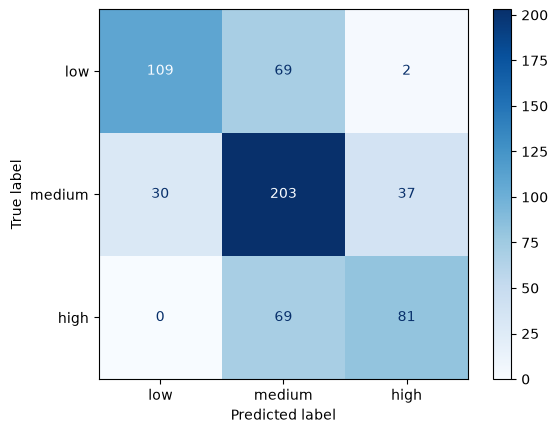

trechos high previstos como low (erro perigoso): 0 de 150


In [7]:
pred = model.predict(X_test)
macro_f1 = f1_score(y_test, pred, average="macro")
base_f1 = f1_score(y_test, DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test), average="macro")
print(classification_report(y_test, pred, labels=["low", "medium", "high"]))
print(f"F1 macro teste = {macro_f1:.3f} | baseline = {base_f1:.3f}")
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=["low", "medium", "high"], cmap="Blues")
plt.show()

dangerous = ((y_test == "high") & (pred == "low")).sum()
print("trechos high previstos como low (erro perigoso):", dangerous, "de", (y_test == "high").sum())

In [8]:
imp = permutation_importance(model, X_test, y_test, scoring="f1_macro", n_repeats=10, random_state=SEED)
order = np.argsort(imp.importances_mean)[::-1][:8]
for i in order:
    print(f"{X.columns[i]:28s} {imp.importances_mean[i]:.3f}")

tactile_paving               0.124
profile                      0.119
obstacles_per_100m           0.070
segment_type                 0.066
visual_alerts                0.044
sidewalk_width_m             0.022
lighting_lux                 0.019
slope_pct                    0.019


A importância por permutação confirma que o modelo usa o que a regra de simulação previa (piso tátil, tráfego, obstáculos, sinais). Se uma variável irrelevante aparecesse no topo, isso indicaria vazamento ou ruído sendo decorado.

In [9]:
joblib.dump(model, "model.joblib")
with open("metrics.json", "w") as f:
    json.dump({"model": best_name, "f1_macro_test": round(macro_f1, 4), "f1_macro_baseline": round(base_f1, 4),
               "cv_f1_macro": {k: round(v[0], 4) for k, v in cv_scores.items()},
               "dangerous_errors": int(dangerous)}, f, indent=2, ensure_ascii=False)
print(open("metrics.json").read())

{
  "model": "random forest",
  "f1_macro_test": 0.6493,
  "f1_macro_baseline": 0.2069,
  "cv_f1_macro": {
    "baseline (classe mais comum)": 0.2069,
    "regressão logística": 0.6025,
    "random forest": 0.6419,
    "gradient boosting": 0.621
  },
  "dangerous_errors": 0
}


## 5. Integração na solução

`predict.py` carrega o modelo salvo e avalia uma rota trecho a trecho para um perfil. A rota recebe o pior nível entre os trechos, porque basta uma travessia perigosa para a rota inteira ser ruim. É essa função que a tela de navegação da CitizenTech chamaria.

In [10]:
import predict
route_a = [
    {"segment_type": "sidewalk", "tactile_paving": 1, "audible_signal": 0, "visual_signal": 0, "braille_signage": 0,
     "visual_alerts": 0, "sidewalk_width_m": 2.4, "obstacles_per_100m": 1, "slope_pct": 3.0,
     "ambient_noise_db": 62.0, "lighting_lux": 50.0, "traffic_vehicles_per_min": 8},
    {"segment_type": "crossing", "tactile_paving": 1, "audible_signal": 1, "visual_signal": 1, "braille_signage": 1,
     "visual_alerts": 1, "sidewalk_width_m": 2.0, "obstacles_per_100m": 0, "slope_pct": 2.0,
     "ambient_noise_db": 66.0, "lighting_lux": 60.0, "traffic_vehicles_per_min": 10},
]
route_b = [
    {"segment_type": "crossing", "tactile_paving": 0, "audible_signal": 0, "visual_signal": 0, "braille_signage": 0,
     "visual_alerts": 0, "sidewalk_width_m": 1.0, "obstacles_per_100m": 6, "slope_pct": 12.0,
     "ambient_noise_db": 85.0, "lighting_lux": 8.0, "traffic_vehicles_per_min": 25},
]
for name, route in [("A", route_a), ("B", route_b)]:
    for profile in ("blind", "deaf"):
        print(name, predict.rate_route(route, profile))

A {'profile': 'blind', 'segment_levels': ['low', 'low'], 'route_level': 'low'}
A {'profile': 'deaf', 'segment_levels': ['medium', 'low'], 'route_level': 'medium'}


B {'profile': 'blind', 'segment_levels': ['high'], 'route_level': 'high'}
B {'profile': 'deaf', 'segment_levels': ['high'], 'route_level': 'high'}


## 6. Limites e próximos passos

* Os dados são simulados e o rótulo vem de uma regra minha. A métrica prova que o pipeline funciona, não que o modelo acerta numa cidade real.
* O próximo passo com mais valor é trocar a simulação por dados coletados: mapeamento de calçadas e semáforos (por exemplo OpenStreetMap) e relatos de usuários da própria CitizenTech.
* Pessoas com surdocegueira dependem de outros sinais e ficam fora deste modelo.
* O erro mais caro é prever `low` para um trecho `high`. Num produto real eu ajustaria o limiar de decisão para errar para o lado seguro.